# Hyperparameter Tuning using GridSearchCV

A Machine Learning model is defined as a mathematical model with a number of parameters that need to be learned from the data. However, there are some parameters, known as <b>Hyperparameters</b> and those cannot be directly learned. They are commonly chosen by humans based on some intuition or hit and trial before the actual training begins. These parameters exhibit their importance by improving the performance of the model such as its complexity or its learning rate. Models can have many hyper-parameters and finding the best combination of parameters can be treated as a search problem.

<b>SVM</b> also has some hyper-parameters (like what C or gamma values to use) and finding optimal hyper-parameter is a very hard task to solve. But it can be found by just trying all combinations and see what parameters work best. The main idea behind it is to create a grid of hyper-parameters and just try all of their combinations (hence, this method is called <b>Gridsearch</b>, But don’t worry! we don’t have to do it manually because Scikit-learn has this functionality built-in with GridSearchCV.

<b>GridSearchCV</b> takes a dictionary that describes the parameters that could be tried on a model to train it. The grid of parameters is defined as a dictionary, where the keys are the parameters and the values are the settings to be tested.
This article demonstrates how to use the <b>GridSearchCV</b> searching method to find optimal hyper-parameters and hence improve the accuracy/prediction results 

We’ll use the built-in breast cancer dataset from Scikit Learn. We can get with the load function:

In [1]:
import pandas as pd
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.datasets import load_breast_cancer
from sklearn.svm import SVC
  
cancer = load_breast_cancer()
  
# The data set is presented in a dictionary form:
print(cancer.keys())

dict_keys(['data', 'target', 'frame', 'target_names', 'DESCR', 'feature_names', 'filename', 'data_module'])


Now we will extract all features into the new data frame and our target features into separate data frames. 

In [2]:
df_feat = pd.DataFrame(cancer['data'],
                       columns = cancer['feature_names'])
  
# cancer column is our target
df_target = pd.DataFrame(cancer['target'], 
                     columns =['Cancer'])
  
print("Feature Variables: ")
print(df_feat.info())

Feature Variables: 
<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 30 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error 

In [3]:
print("Dataframe looks like : ")
print(df_feat.head())

Dataframe looks like : 
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst radius  worst texture  worst p

#### Train Test Split

Now we will split our data into train and test set with a 70: 30 ratio 

In [4]:
from sklearn.model_selection import train_test_split
  
X_train, X_test, y_train, y_test = train_test_split( df_feat, np.ravel(df_target), test_size = 0.30, random_state = 101)

#### Train the Support Vector Classifier without Hyper-parameter Tuning 

First, we will train our model by calling the standard SVC() function without doing Hyperparameter Tuning and see its classification and confusion matrix. 

In [5]:
# train the model on train set
model = SVC()
model.fit(X_train, y_train)
  
# print prediction results
predictions = model.predict(X_test)
print(classification_report(y_test, predictions))

              precision    recall  f1-score   support

           0       0.95      0.85      0.90        66
           1       0.91      0.97      0.94       105

    accuracy                           0.92       171
   macro avg       0.93      0.91      0.92       171
weighted avg       0.93      0.92      0.92       171



<b>What are your remarks ?</b>

#### Remarques

- Le `SVC()` par défaut obtient **92 %** d'accuracy sur le jeu de test, sans réglage.
- Il est **déséquilibré selon les classes** : très bon rappel pour la classe 1 (*bénigne*, 97 %) mais seulement **85 %** pour la classe 0 (*maligne*) : 10 tumeurs malignes sur 66 sont prises pour bénignes. C'est l'erreur la plus grave en pratique. Cela s'explique par le déséquilibre des classes (≈ 63 % de bénignes) et par le fait que les variables ne sont **pas normalisées** (des variables comme `area` valent plusieurs centaines ou milliers alors que d'autres sont de l'ordre de 0.1 : elles dominent le calcul de distance du noyau RBF).
- Il est possible de faire mieux en réglant `C`, `gamma` et le noyau, ce que fait GridSearchCV.

### Use GridsearchCV

One of the great things about GridSearchCV is that it is a meta-estimator. It takes an estimator like SVC and creates a new estimator, that behaves exactly the same – in this case, like a classifier. You should add refit=True and choose verbose to whatever number you want, the higher the number, the more verbose (verbose just means the text output describing the process).

In [6]:
from sklearn.model_selection import GridSearchCV
  
# defining parameter range
param_grid = {'C': [0.1, 1, 10, 100, 1000], 
              'gamma': [1, 0.1, 0.01, 0.001, 0.0001],
              'kernel': ['rbf']} 
  
grid = GridSearchCV(SVC(), param_grid, refit = True, verbose = 3)
  
# fitting the model for grid search
grid.fit(X_train, y_train)

Fitting 5 folds for each of 25 candidates, totalling 125 fits
[CV 1/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 2/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 3/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.625 total time=   0.0s
[CV 4/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 5/5] END ........C=0.1, gamma=1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 2/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 3/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.625 total time=   0.0s
[CV 4/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 5/5] END ......C=0.1, gamma=0.1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END .....C=0.1, gamma=0.01, kernel=rbf;, score=0.637 total time=   0.0s
[CV 2/5] END .....C=0.1, gamma=0.01, kernel=rbf

[CV 3/5] END ....C=0.1, gamma=0.001, kernel=rbf;, score=0.625 total time=   0.0s
[CV 4/5] END ....C=0.1, gamma=0.001, kernel=rbf;, score=0.633 total time=   0.0s
[CV 5/5] END ....C=0.1, gamma=0.001, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.887 total time=   0.0s
[CV 2/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.938 total time=   0.0s


[CV 3/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.963 total time=   0.0s


[CV 4/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.962 total time=   0.0s
[CV 5/5] END ...C=0.1, gamma=0.0001, kernel=rbf;, score=0.886 total time=   0.0s
[CV 1/5] END ..........C=1, gamma=1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 2/5] END ..........C=1, gamma=1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 3/5] END ..........C=1, gamma=1, kernel=rbf;, score=0.625 total time=   0.0s


[CV 4/5] END ..........C=1, gamma=1, kernel=rbf;, score=0.633 total time=   0.0s


[CV 5/5] END ..........C=1, gamma=1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 2/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 3/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.625 total time=   0.0s
[CV 4/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 5/5] END ........C=1, gamma=0.1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.637 total time=   0.0s
[CV 2/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.637 total time=   0.0s
[CV 3/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.625 total time=   0.0s
[CV 4/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.633 total time=   0.0s
[CV 5/5] END .......C=1, gamma=0.01, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END ......C=1, gamma=0.001, kernel=rbf;, score=0.900 total time=   0.0s
[CV 2/5] END ......C=1, gamm

... (7 outputs left out)

[CV 4/5] END .......C=1000, gamma=1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 5/5] END .......C=1000, gamma=1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.637 total time=   0.0s
[CV 2/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.637 total time=   0.0s


[CV 3/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.625 total time=   0.0s
[CV 4/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 5/5] END .....C=1000, gamma=0.1, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.637 total time=   0.0s
[CV 2/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.637 total time=   0.0s


[CV 3/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.613 total time=   0.0s
[CV 4/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.633 total time=   0.0s
[CV 5/5] END ....C=1000, gamma=0.01, kernel=rbf;, score=0.633 total time=   0.0s
[CV 1/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.887 total time=   0.0s
[CV 2/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.912 total time=   0.0s
[CV 3/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.900 total time=   0.0s
[CV 4/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.937 total time=   0.0s
[CV 5/5] END ...C=1000, gamma=0.001, kernel=rbf;, score=0.924 total time=   0.0s
[CV 1/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.938 total time=   0.0s
[CV 2/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.912 total time=   0.0s
[CV 3/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.963 total time=   0.0s
[CV 4/5] END ..C=1000, gamma=0.0001, kernel=rbf;, score=0.924 total time=   0.0s
[CV 5/5] END ..C=1000, gamma

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",SVC()
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'C': [0.1, 1, ...], 'gamma': [1, 0.1, ...], 'kernel': ['rbf']}"
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",3
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",None
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is u

What fit does is a bit more involved than usual. First, it runs the same loop with cross-validation, to find the best parameter combination. Once it has the best combination, it runs fit again on all data passed to fit (without cross-validation), to build a single new model using the best parameter setting.
You can inspect the best parameters found by GridSearchCV in the best_params_ attribute, and the best estimator in the best_estimator_ attribute: 

In [7]:
# print best parameter after tuning
print(grid.best_params_)
  
# print how our model looks after hyper-parameter tuning
print(grid.best_estimator_)

{'C': 1, 'gamma': 0.0001, 'kernel': 'rbf'}
SVC(C=1, gamma=0.0001)


## Activity

- Re-run predictions using the grid search parameters to obtain the best possible performance.

In [8]:
# Prédictions avec les meilleurs paramètres trouvés par GridSearchCV
grid_predictions = grid.predict(X_test)

print('Meilleurs paramètres :', grid.best_params_)
print('Meilleure accuracy en validation croisée (train) : %.4f' % grid.best_score_)
print('\nMatrice de confusion (lignes = vrai, colonnes = prédit) :')
print(confusion_matrix(y_test, grid_predictions))
print('\n', classification_report(y_test, grid_predictions))

Meilleurs paramètres : {'C': 1, 'gamma': 0.0001, 'kernel': 'rbf'}
Meilleure accuracy en validation croisée (train) : 0.9472

Matrice de confusion (lignes = vrai, colonnes = prédit) :
[[ 59   7]
 [  4 101]]

               precision    recall  f1-score   support

           0       0.94      0.89      0.91        66
           1       0.94      0.96      0.95       105

    accuracy                           0.94       171
   macro avg       0.94      0.93      0.93       171
weighted avg       0.94      0.94      0.94       171



**Comparaison avant / après GridSearchCV** sur le même jeu de test :

,accuracy,précision,rappel,F1
modèle,,,,
SVC() par défaut,0.9240,0.9107,0.9714,0.9401
SVC + GridSearchCV (rbf),0.9357,0.9352,0.9619,0.9484


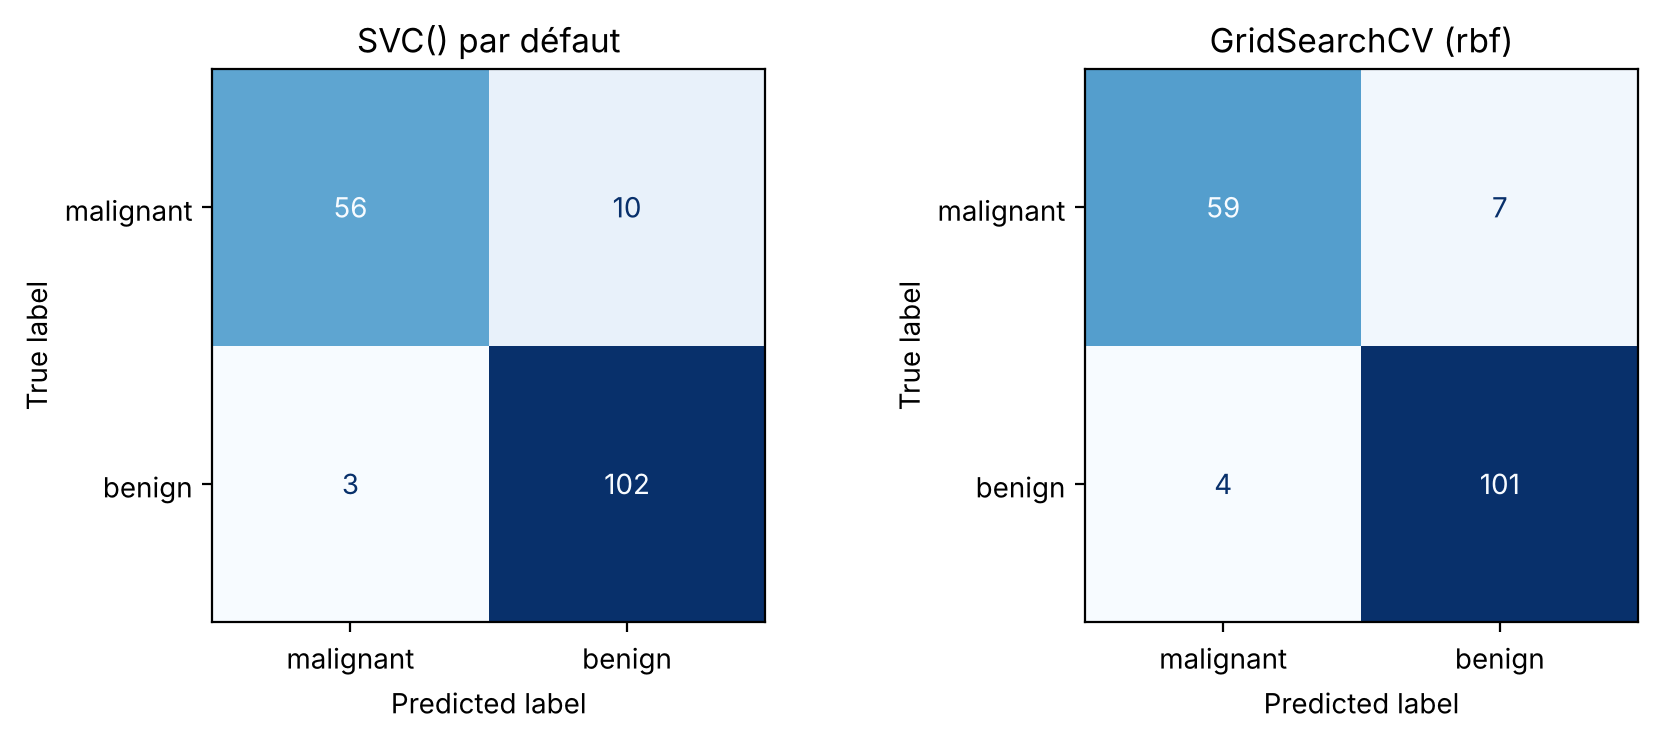

In [9]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

def summary(name, yp):
    return dict(modèle=name, accuracy=accuracy_score(y_test, yp), précision=precision_score(y_test, yp),
                rappel=recall_score(y_test, yp), F1=f1_score(y_test, yp))
comp = pd.DataFrame([summary('SVC() par défaut', predictions), summary('SVC + GridSearchCV (rbf)', grid_predictions)]).set_index('modèle')
display(comp.round(4))

fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, (t, p) in zip(ax, [('SVC() par défaut', predictions), ('GridSearchCV (rbf)', grid_predictions)]):
    ConfusionMatrixDisplay.from_predictions(y_test, p, display_labels=cancer.target_names, cmap='Blues', ax=a, colorbar=False); a.set_title(t)
plt.tight_layout(); plt.show()

#### Remarques

- La grille explore 25 combinaisons (5 valeurs de C × 5 de gamma, 5 plis chacune = 125 entraînements). Meilleurs paramètres : **C = 1, gamma = 0.0001, noyau rbf**, avec une accuracy CV de **94.7 %** sur le jeu d'entraînement.
- Sur le jeu de test, l'accuracy passe de **92.4 % à 93.6 %** : précision de 0.91 à 0.94 pour la classe positive, F1 de 0.940 à 0.948. Il y a 7 tumeurs malignes prises pour bénignes au lieu de 10 : c'est mieux, mais l'amélioration reste modeste (≈ 2 exemples sur 171).
- ⚠️ La meilleure valeur de `gamma` (0.0001) est **au bord de la grille** : le véritable optimum est peut-être en dehors, ce qui suggère d'élargir la grille. De plus, avec des variables non normalisées, GridSearchCV compense mal : voir ci-dessous.
- Le jeu de test n'a servi **qu'à l'évaluation finale** : le réglage des hyper-paramètres s'est fait uniquement par validation croisée sur le train, donc cette accuracy n'est pas biaisée par le choix des paramètres.

### Pour aller plus loin : standardisation + grille plus large

Les 30 variables du dataset ont des échelles très différentes (de ~0.01 à ~2500). Un SVM à noyau RBF est basé sur des distances : les variables à grande échelle dominent. On place un `StandardScaler` dans un `Pipeline` (ajusté uniquement sur les plis d'entraînement, donc sans fuite d'information) et on élargit la grille (noyaux `rbf`, `linear`, `poly`).

In [10]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pipe = Pipeline([('scaler', StandardScaler()), ('svc', SVC())])
param_grid2 = [
 {'svc__kernel': ['rbf'],    'svc__C': [0.1, 1, 10, 100, 1000], 'svc__gamma': [1, 0.1, 0.01, 0.001, 0.0001]},
 {'svc__kernel': ['linear'], 'svc__C': [0.001, 0.01, 0.1, 1, 10, 100]},
 {'svc__kernel': ['poly'],   'svc__C': [0.1, 1, 10], 'svc__degree': [2, 3], 'svc__gamma': ['scale', 0.01]},
]
grid2 = GridSearchCV(pipe, param_grid2, cv=5, refit=True, n_jobs=-1)
grid2.fit(X_train, y_train)
print('Meilleurs paramètres :', grid2.best_params_)
print('Accuracy CV (train) : %.4f' % grid2.best_score_)
p2 = grid2.predict(X_test)
print('\nMatrice de confusion :\n', confusion_matrix(y_test, p2))
print('\n', classification_report(y_test, p2))
comp2 = pd.DataFrame([summary('SVC() par défaut', predictions), summary('GridSearchCV (sans scaling)', grid_predictions),
                      summary('Scaler + GridSearchCV élargi', p2)]).set_index('modèle')
display(comp2.round(4))

Meilleurs paramètres : {'svc__C': 0.1, 'svc__kernel': 'linear'}
Accuracy CV (train) : 0.9824

Matrice de confusion :
 [[ 61   5]
 [  0 105]]

               precision    recall  f1-score   support

           0       1.00      0.92      0.96        66
           1       0.95      1.00      0.98       105

    accuracy                           0.97       171
   macro avg       0.98      0.96      0.97       171
weighted avg       0.97      0.97      0.97       171



,accuracy,précision,rappel,F1
modèle,,,,
SVC() par défaut,0.9240,0.9107,0.9714,0.9401
GridSearchCV (sans scaling),0.9357,0.9352,0.9619,0.9484
Scaler + GridSearchCV élargi,0.9708,0.9545,1.0000,0.9767


#### Remarques

- **La standardisation change tout** : après `StandardScaler` et une grille plus large, le meilleur modèle est un SVM **linéaire** avec `C = 0.1` (accuracy CV 98.2 %), qui obtient **97.1 %** en test contre 93.6 % sans standardisation (et 92.4 % pour le `SVC()` par défaut).
- Pour la classe *maligne* : le rappel passe de 85 % (défaut) à 89 % (GridSearchCV simple) puis à **92 %** (standardisation + grille élargie). Il reste **5 tumeurs malignes prises pour bénignes** (sur 66), contre 10 au départ. Aucune tumeur bénigne n'est classée comme maligne (rappel de 1.00 pour la classe bénigne). En contexte médical, on chercherait à réduire encore ces faux négatifs (par exemple en pondérant la classe maligne avec `class_weight`).
- Le fait que le noyau **linéaire** gagne indique que les 30 variables rendent les classes quasi linéairement séparables : cohérent avec le Lab 2 (linéaire préférable quand le nombre de variables est grand).
- Le `Pipeline` garantit que la standardisation est apprise **uniquement sur les plis d'entraînement** à chaque étape de la validation croisée : il n'y a pas de fuite d'information du pli de validation.
- **À retenir** : (1) standardiser les variables pour un SVM, (2) vérifier que l'optimum n'est pas au bord de la grille, (3) comparer plusieurs noyaux, (4) évaluer sur un jeu de test jamais utilisé pour le réglage.